In [5]:
#mount
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
#downloaded dataset and 12 classes
!pip -q install fiftyone
import fiftyone as fo
fo.config.dataset_zoo_dir = '/content/drive/MyDrive/coco_seg/fiftyone'
classes = ['person', 'car', 'dog', 'cat', 'chair', 'bottle',
           'bus', 'bicycle', 'horse', 'cup', 'laptop', 'bird']
print('Setup OK. Classes:', len(classes))

Setup OK. Classes: 12


In [12]:
# reload datasets
# run again after cell 4 to redownload the deleted images
import fiftyone.zoo as foz
train = foz.load_zoo_dataset('coco-2017', split='train', label_types=['segmentations'], classes=classes, max_samples=8000, seed=42, shuffle=True)
val = foz.load_zoo_dataset('coco-2017', split='validation', label_types=['segmentations'], classes=classes, max_samples=2000, seed=42, shuffle=True)

import random
random.seed(42)
ids = val.values('id')
random.shuffle(ids)
half = len(ids)//2
val_split = val.select(ids[:half])
test_split = val.select(ids[half:])
print(len(train), len(val_split), len(test_split))

INFO:fiftyone.zoo.datasets:Downloading split 'train' to '/content/drive/MyDrive/coco_seg/fiftyone/coco-2017/train' if necessary


Found annotations at '/content/drive/MyDrive/coco_seg/fiftyone/coco-2017/raw/instances_train2017.json'


INFO:fiftyone.utils.coco:Found annotations at '/content/drive/MyDrive/coco_seg/fiftyone/coco-2017/raw/instances_train2017.json'


7999 images found; downloading the remaining 1


INFO:fiftyone.utils.coco:7999 images found; downloading the remaining 1


 100% |██████████████████████| 1/1 [343.3ms elapsed, 0s remaining, 3.0 images/s] 


... (13 outputs left out)

INFO:fiftyone.zoo.datasets:Existing download of split 'validation' is sufficient


Loading existing dataset 'coco-2017-validation-2000'. To reload from disk, either delete the existing dataset or provide a custom `dataset_name` to use


INFO:fiftyone.zoo.datasets:Loading existing dataset 'coco-2017-validation-2000'. To reload from disk, either delete the existing dataset or provide a custom `dataset_name` to use


8000 1000 1000


In [8]:
#deletes the broken image downloads
import os
from PIL import Image
bad = []
root = '/content/drive/MyDrive/coco_seg/fiftyone/coco-2017'
for dirpath, _, files in os.walk(root):
    for fn in files:
        if fn.lower().endswith('.jpg'):
            fp = os.path.join(dirpath, fn)
            try:
                with Image.open(fp) as im:
                    im.verify()
            except Exception:
                bad.append(fp)
for fp in bad:
    os.remove(fp)
print('deleted broken files:', len(bad), bad[:10])

deleted broken files: 0 []


In [13]:
#rebuild the split
import random
random.seed(42)
ids = val.values('id')
random.shuffle(ids)
val_split = val.select(ids[:1000])
test_split = val.select(ids[1000:])
print('val_split:', len(val_split), '| test_split:', len(test_split), '(expect 1000 and 1000)')

val_split: 1000 | test_split: 1000 (expect 1000 and 1000)


In [14]:
# create the masks
import os
import numpy as np
from PIL import Image
from tqdm.auto import tqdm

CLASS_TO_ID = {name: i + 1 for i, name in enumerate(classes)}
MASK_ROOT = '/content/drive/MyDrive/coco_seg/masks'

def render_mask(sample):
    """Build one mask image: every pixel gets its class number (0 = background)."""
    img = Image.open(sample.filepath)
    w, h = img.size
    mask = np.zeros((h, w), dtype=np.uint8)          # start as all background
    detections = sample.ground_truth.detections if sample.ground_truth else []
    # Paint BIGGEST objects first, so a small object in front of a big one
    # keeps its own pixels instead of being swallowed.
    detections = sorted(detections, key=lambda d: d.bounding_box[2] * d.bounding_box[3], reverse=True)
    for det in detections:
        if det.label not in CLASS_TO_ID or det.mask is None:
            continue                                # ignore anything outside our 12 classes
        x, y, bw, bh = det.bounding_box             # box position as fractions of the image
        x0 = max(int(round(x * w)), 0)
        y0 = max(int(round(y * h)), 0)
        piece = np.asarray(det.mask)                # True/False grid of the object inside its box
        ph, pw = piece.shape
        x1, y1 = min(x0 + pw, w), min(y0 + ph, h)   # clip boxes that spill off the image edge
        if x1 <= x0 or y1 <= y0:
            continue
        region = mask[y0:y1, x0:x1]
        piece = piece[:y1 - y0, :x1 - x0]
        region[piece] = CLASS_TO_ID[det.label]      # stamp the class number onto the pixels
    return mask

splits = {'train': train, 'val': val_split, 'test': test_split}
index_rows = ['split,image_path,mask_path']
made, skipped = 0, 0
for split_name, view in splits.items():
    out_dir = os.path.join(MASK_ROOT, split_name)
    os.makedirs(out_dir, exist_ok=True)
    for sample in tqdm(view, desc=split_name + ' masks'):
        stem = os.path.splitext(os.path.basename(sample.filepath))[0]
        mask_path = os.path.join(out_dir, stem + '.png')
        if not os.path.exists(mask_path):           # resume-friendly: skip masks already saved
            Image.fromarray(render_mask(sample)).save(mask_path)
            made += 1
        else:
            skipped += 1
        index_rows.append(f'{split_name},{sample.filepath},{mask_path}')

with open('/content/drive/MyDrive/coco_seg/masks_index.csv', 'w') as f:
    f.write('\n'.join(index_rows))
print(f'Done! Saved {made} new masks ({skipped} already existed).')
print('Masks live in:', MASK_ROOT, '(folders: train, val, test)')
print('Index file: /content/drive/MyDrive/coco_seg/masks_index.csv')


train masks:   0%|          | 0/8000 [00:00<?, ?it/s]

val masks:   0%|          | 0/1000 [00:00<?, ?it/s]

test masks:   0%|          | 0/1000 [00:00<?, ?it/s]

Done! Saved 7997 new masks (2003 already existed).
Masks live in: /content/drive/MyDrive/coco_seg/masks (folders: train, val, test)
Index file: /content/drive/MyDrive/coco_seg/masks_index.csv


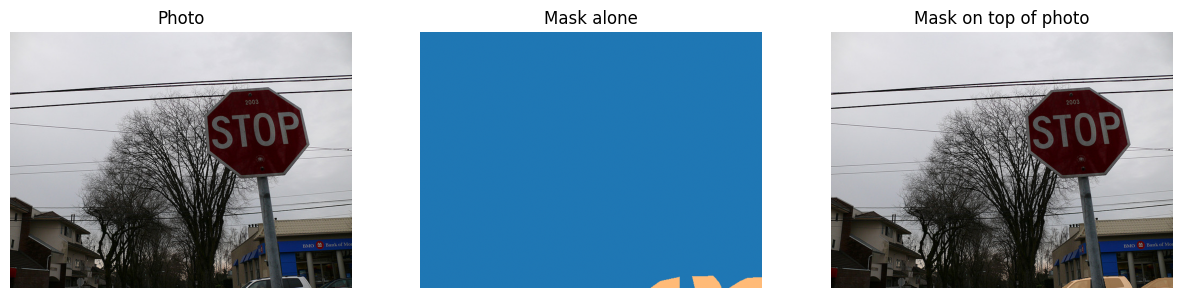

Class numbers in this mask: [0, 2]  (0 = background; 1-12 follow the classes list)


In [15]:
import matplotlib.pyplot as plt

sample = train.take(1).first()                       # one random training image
stem = os.path.splitext(os.path.basename(sample.filepath))[0]
mask = np.array(Image.open(os.path.join(MASK_ROOT, 'train', stem + '.png')))
img = Image.open(sample.filepath)

# hide background pixels so only the objects get coloured on the overlay
mask_colours = np.ma.masked_where(mask == 0, mask)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img);                        axes[0].set_title('Photo')
axes[1].imshow(mask, cmap='tab20', vmin=0, vmax=12); axes[1].set_title('Mask alone')
axes[2].imshow(img)
axes[2].imshow(mask_colours, cmap='tab20', alpha=0.55, vmin=0, vmax=12)
axes[2].set_title('Mask on top of photo')
for ax in axes:
    ax.axis('off')
plt.show()

print('Class numbers in this mask:', sorted(np.unique(mask).tolist()),
      ' (0 = background; 1-12 follow the classes list)')

counting train:   0%|          | 0/8000 [00:00<?, ?it/s]

counting val:   0%|          | 0/1000 [00:00<?, ?it/s]

counting test:   0%|          | 0/1000 [00:00<?, ?it/s]

     class     pixels  percent
background 2251901059  81.6552
    person  328845500  11.9241
       car   23524691   0.8530
       dog   20158060   0.7309
       cat   22302407   0.8087
     chair   24000046   0.8703
    bottle    7816948   0.2834
       bus   28655271   1.0391
   bicycle    6336590   0.2298
     horse   11141371   0.4040
       cup   10724414   0.3889
    laptop   15747698   0.5710
      bird    6663566   0.2416


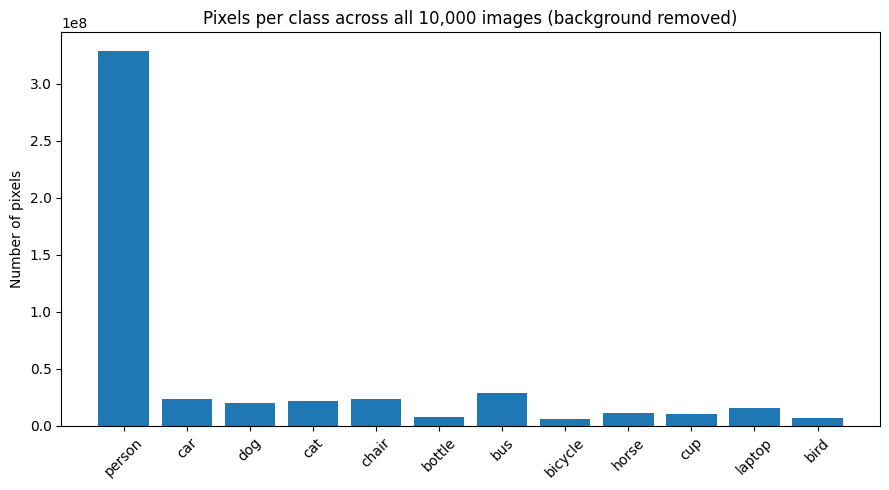


                                  thing     value
                           train images      8000
                      validation images      1000
                            test images      1000
 number of classes (without background)        12
most common image size (width x height) 640 x 480
             image width range (pixels) 150 - 640
            image height range (pixels) 120 - 640

Saved to Drive: dataset_summary.csv, class_pixel_distribution.csv, class_distribution.png


In [17]:
# Dataset statistics for the report (saved to Drive as CSV + chart).

from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

# --- images per split + image sizes ---
counts = {name: len(view) for name, view in splits.items()}
sizes = Counter()
for view in splits.values():
    for s in view:
        with Image.open(s.filepath) as im:
            sizes[im.size] += 1                     # reading the size does not load the photo
common_size = sizes.most_common(1)[0][0]
min_w, max_w = min(s[0] for s in sizes), max(s[0] for s in sizes)
min_h, max_h = min(s[1] for s in sizes), max(s[1] for s in sizes)

# --- pixels per class, across every mask ---
pixel_counts = np.zeros(len(classes) + 1, dtype=np.int64)
for split_name in splits:
    out_dir = os.path.join(MASK_ROOT, split_name)
    for fn in tqdm(sorted(os.listdir(out_dir)), desc='counting ' + split_name):
        m = np.array(Image.open(os.path.join(out_dir, fn)))
        pixel_counts += np.bincount(m.ravel(), minlength=len(classes) + 1)

names = ['background'] + classes
total = int(pixel_counts.sum())
dist = pd.DataFrame({
    'class': names,
    'pixels': pixel_counts,
    'percent': [round(100 * p / total, 4) for p in pixel_counts],
})
dist.to_csv('/content/drive/MyDrive/coco_seg/class_pixel_distribution.csv', index=False)
print(dist.to_string(index=False))

# --- bar chart of the imbalance (without background, or it would hide everything) ---
no_bg = dist[dist['class'] != 'background']
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(no_bg['class'], no_bg['pixels'])
ax.set_title('Pixels per class across all 10,000 images (background removed)')
ax.set_ylabel('Number of pixels')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/coco_seg/class_distribution.png', dpi=150)
plt.show()

# --- one summary table for the report ---
summary = pd.DataFrame({
    'thing': ['train images', 'validation images', 'test images',
              'number of classes (without background)',
              'most common image size (width x height)',
              'image width range (pixels)', 'image height range (pixels)'],
    'value': [counts['train'], counts['val'], counts['test'], len(classes),
              f'{common_size[0]} x {common_size[1]}', f'{min_w} - {max_w}', f'{min_h} - {max_h}'],
})
summary.to_csv('/content/drive/MyDrive/coco_seg/dataset_summary.csv', index=False)
print()
print(summary.to_string(index=False))
print()
print('Saved to Drive: dataset_summary.csv, class_pixel_distribution.csv, class_distribution.png')

In [20]:
import glob
print(glob.glob('/content/drive/MyDrive/coco_seg/**/*.csv', recursive=True))
print(glob.glob('/content/**/*.csv', recursive=True))

['/content/drive/MyDrive/coco_seg/masks_index.csv', '/content/drive/MyDrive/coco_seg/class_pixel_distribution.csv', '/content/drive/MyDrive/coco_seg/dataset_summary.csv']
['/content/drive/MyDrive/IPL Matches Cleaned.csv', '/content/drive/MyDrive/IPL Processed.csv', '/content/drive/MyDrive/results.csv', '/content/drive/MyDrive/2401CS17/attendance.csv', '/content/drive/MyDrive/2401CS17/students.csv', '/content/drive/MyDrive/2401CS17/complaints.csv', '/content/drive/MyDrive/coco_seg/masks_index.csv', '/content/drive/MyDrive/coco_seg/class_pixel_distribution.csv', '/content/drive/MyDrive/coco_seg/dataset_summary.csv', '/content/sample_data/mnist_test.csv', '/content/sample_data/mnist_train_small.csv', '/content/sample_data/california_housing_test.csv', '/content/sample_data/california_housing_train.csv']
